In [13]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [14]:
df =pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df =df[['price','bedrooms','baths',"Area Size"]].dropna()

In [15]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [16]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

In [17]:
X=df[['price','bedrooms','baths',"Area Size"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

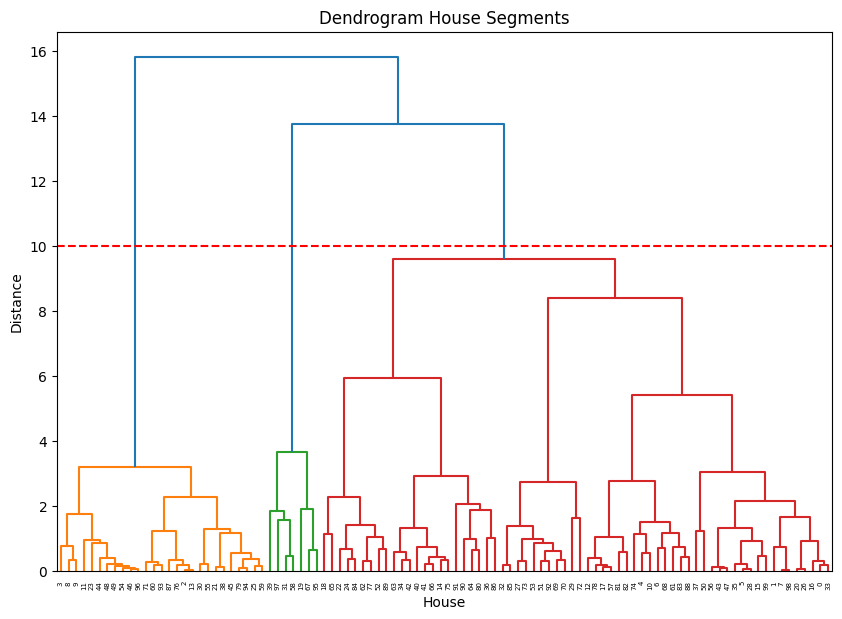

In [18]:
linked = linkage(X_scaled, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram House Segments')
plt.xlabel('House')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [19]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df["HC_Cluster"] = hc.fit_predict(X_scaled)

In [20]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(1))

HC_Cluster
0    66
1    27
2     7
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0            20900000.0       4.4    4.9        6.4
1             6257037.0       2.1    2.1        3.7
2           115571428.6       6.1    6.9        1.5


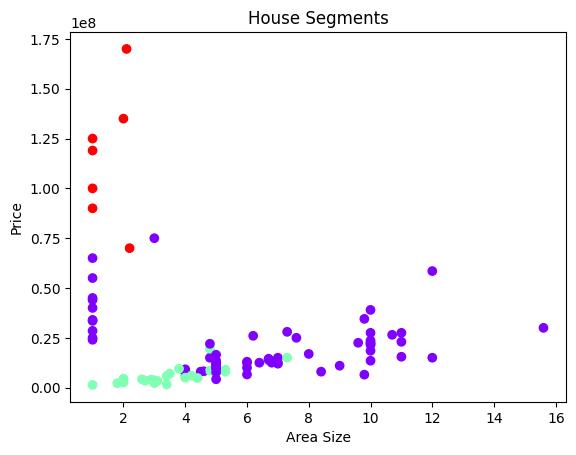

In [21]:
plt.scatter(df['Area Size'],df['price'],c=df['HC_Cluster'],cmap='rainbow')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments')
plt.show()